# Day 08 — Chạy model pre-label trên Google Colab (cho máy yếu)

**Dùng khi:** laptop không GPU hoặc quá chậm. Colab cho GPU miễn phí (T4) để **chạy model** (Part 2–5). **CVAT, review, đo số, viết báo cáo vẫn làm trên máy bạn.**

**Luồng:** Colab chạy `prelabel.py` → tải `colab_outputs.zip` về → nạp file nhãn vào CVAT (cách A, `docs/CVAT_AI.md`) → review → các script đo (`review_stats.py`...) chạy trên máy bạn (nhẹ, không cần GPU).

> Colab **không** nối được tới CVAT `localhost` của bạn: ta chỉ lấy file nhãn từ Colab. Bài vẫn là **cá nhân**: commit từ repo trên máy bạn.

**Trước khi chạy:** menu **Runtime → Change runtime type → T4 GPU**. Chạy các ô từ trên xuống.

## 0. Kiểm tra GPU và lấy mã nguồn

In [2]:
!nvidia-smi -L || echo "Không có GPU: vào Runtime > Change runtime type > T4 GPU"
import os
REPO_URL = "https://github.com/VinUni-AI20k/K5-L23-Day08-AI-Assisted-Labeling.git"   # có thể đổi thành repo fork của bạn (public)
if not os.path.isdir("lab"):
    !git clone -q $REPO_URL lab
%cd lab
!ls

GPU 0: NVIDIA GeForce RTX 3060 Laptop GPU (UUID: GPU-3f28ba51-ebd7-8e21-7b4d-04f539329563)
d:\Vin\Day08\K5-L23-Day08-HoXuanHung-2A202603062-AI-Assisted-Labeling\notebooks\lab\lab


'ls' is not recognized as an internal or external command,
operable program or batch file.


## 1. Cài thư viện (torch đã có sẵn trên Colab, không cài lại)

In [3]:
!pip -q install "ultralytics>=8.4.0" opencv-python-headless pyyaml matplotlib "transformers>=5.0" huggingface_hub
!python scripts/check_env.py || true

[PASS] Python 3.12.2
[PASS] numpy 2.5.4
[PASS] PIL 13.0.0
[PASS] cv2 5.1.0
[PASS] matplotlib 3.11.2
[PASS] yaml 6.0.3
[PASS] torch 2.15.0+cu132
[PASS] ultralytics 8.4.215
[PASS] transformers 5.23.0
[PASS] GPU CUDA: NVIDIA GeForce RTX 3060 Laptop GPU
[PASS] git
[PASS] data/images: 36/36 ảnh
[PASS] data/split.csv
[WARN] trọng số trong models/: (chưa có)
         -> python scripts/download_models.py --set core
[WARN] HuggingFace token: chưa đăng nhập (chỉ cần cho SAM 3, tuỳ chọn)
         -> xem docs/SETUP.md mục SAM 3

SẴN SÀNG.


## 2. Tải trọng số (bài chính: 3 model, ~0.35 GB)
`core` gồm YOLO26m, YOLOE-26s, **SAM 2.1 base**. SAM là bắt buộc: muốn SAM 1 bỏ comment dòng `--set sam1`.

In [4]:
!python scripts/download_models.py --set core
# !python scripts/download_models.py --set sam1      # tuỳ chọn: SAM 1 (mobile_sam)


OK   yolo26m.pt

OK   yoloe-26s-seg.pt

OK   sam2.1_b.pt


### (Nâng cao, tuỳ chọn) SAM 3
Cần quyền tại https://huggingface.co/facebook/sam3. Lưu token vào **Colab Secrets** (chìa khoá bên trái) tên `HF_TOKEN`, bật *Notebook access*. **Không dán token vào notebook.**

In [5]:
# from google.colab import userdata
# import os
# os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
# !python scripts/download_models.py --set sam3

## 3. Part 2 — Thử 3 model trên 8 ảnh `pilot` (không phải gold)
Mỗi lần chạy ghi một dòng vào `work/runs.csv`. Xem ảnh `viz/` bằng ô kế tiếp rồi ghi `model_log.csv` **trên máy bạn**.

In [6]:
import sys
import time
import subprocess
import torch

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA build của PyTorch:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    print("\n❌ PyTorch chưa sử dụng được GPU.")
    print("Kiểm tra lại bản torch CUDA trong môi trường notebook.")
else:
    device = torch.device("cuda:0")
    print("\n✅ GPU:", torch.cuda.get_device_name(0))
    print("VRAM tổng:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GB")

    # Chạy phép tính lớn để kiểm tra GPU thật sự
    a = torch.randn((4096, 4096), device=device)
    b = torch.randn((4096, 4096), device=device)

    torch.cuda.synchronize()
    start = time.perf_counter()
    c = a @ b
    torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    print("Thiết bị tensor:", c.device)
    print("Thời gian nhân ma trận:", round(elapsed, 3), "giây")
    print("VRAM đang dùng:", round(torch.cuda.memory_allocated(0) / 1024**3, 2), "GB")
    print("\n✅ GPU đang thực sự thực hiện phép tính.")

Python: d:\Vin\Day08\K5-L23-Day08-HoXuanHung-2A202603062-AI-Assisted-Labeling\.venv\Scripts\python.exe
PyTorch: 2.15.0+cu132
CUDA build của PyTorch: 13.2
CUDA available: True

✅ GPU: NVIDIA GeForce RTX 3060 Laptop GPU
VRAM tổng: 6.0 GB
Thiết bị tensor: cuda:0
Thời gian nhân ma trận: 0.151 giây
VRAM đang dùng: 0.19 GB

✅ GPU đang thực sự thực hiện phép tính.


In [7]:
!python scripts/prelabel.py --model yolo26 --size m --split pilot --conf 0.25 --out work/prelabel/t_y26
!python scripts/prelabel.py --model yolo26 --size m --split pilot --conf 0.5  --out work/prelabel/t_y26_c05
!python scripts/prelabel.py --model yoloe --classes three_wheeler --split pilot --conf 0.25 --out work/prelabel/t_yoloe
# SAM (bắt buộc): chọn phiên bản bằng --sam (mobile_sam.pt = SAM 1, sam2.1_b.pt = SAM 2.1)
!python scripts/prelabel.py --model yolo26 --size m --classes "person,motorbike,car" --images img_004.jpg img_013.jpg --conf 0.3 --segmenter sam --sam sam2.1_b.pt --out work/prelabel/t_sam

Model: yolo26 | thiết bị: cuda | 8 ảnh | ngưỡng mặc định 0.25
  img_002.jpg: 20 box
  img_007.jpg: 26 box
  img_011.jpg: 31 box
  img_015.jpg: 19 box
  img_016.jpg: 30 box
  img_019.jpg: 30 box
  img_030.jpg: 36 box
  img_032.jpg: 23 box

Đã ghi 215 box (0 có mask) cho 8 ảnh -> work\prelabel\t_y26\pre.coco.json
Tên thô KHÔNG có trong ánh xạ (bị bỏ im lặng nếu bạn không đọc dòng này!): umbrella×10, handbag×2, traffic light×2, backpack×2
Số box theo lớp: person=131, motorbike=55, car=17, bicycle=8, truck=3, bus=1
Thời gian: nạp 0.6s, chạy 5.1s (0.63s/ảnh)
Ảnh xem nhanh: work\prelabel\t_y26\viz/
Model: yolo26 | thiết bị: cuda | 8 ảnh | ngưỡng mặc định 0.5
  img_002.jpg: 16 box
  img_007.jpg: 11 box
  img_011.jpg: 21 box
  img_015.jpg: 8 box
  img_016.jpg: 22 box
  img_019.jpg: 17 box
  img_030.jpg: 27 box
  img_032.jpg: 18 box

Đã ghi 140 box (0 có mask) cho 8 ảnh -> work\prelabel\t_y26_c05\pre.coco.json
Tên thô KHÔNG có trong ánh xạ (bị bỏ im lặng nếu bạn không đọc dòng này!): umbrella×5

d:\Vin\Day08\K5-L23-Day08-HoXuanHung-2A202603062-AI-Assisted-Labeling\.venv\Lib\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


Model: yolo26 | thiết bị: cuda | 2 ảnh | ngưỡng mặc định 0.3
  img_004.jpg: 7 box
  img_013.jpg: 9 box

Đã ghi 16 box (16 có mask) cho 2 ảnh -> work\prelabel\t_sam\pre.coco.json
Tên thô KHÔNG có trong ánh xạ (bị bỏ im lặng nếu bạn không đọc dòng này!): bottle×8, umbrella×3, handbag×1, chair×1
Số box theo lớp: person=9, car=6, motorbike=1
Thời gian: nạp 1.3s, chạy 5.0s (2.50s/ảnh)
Ảnh xem nhanh: work\prelabel\t_sam\viz/


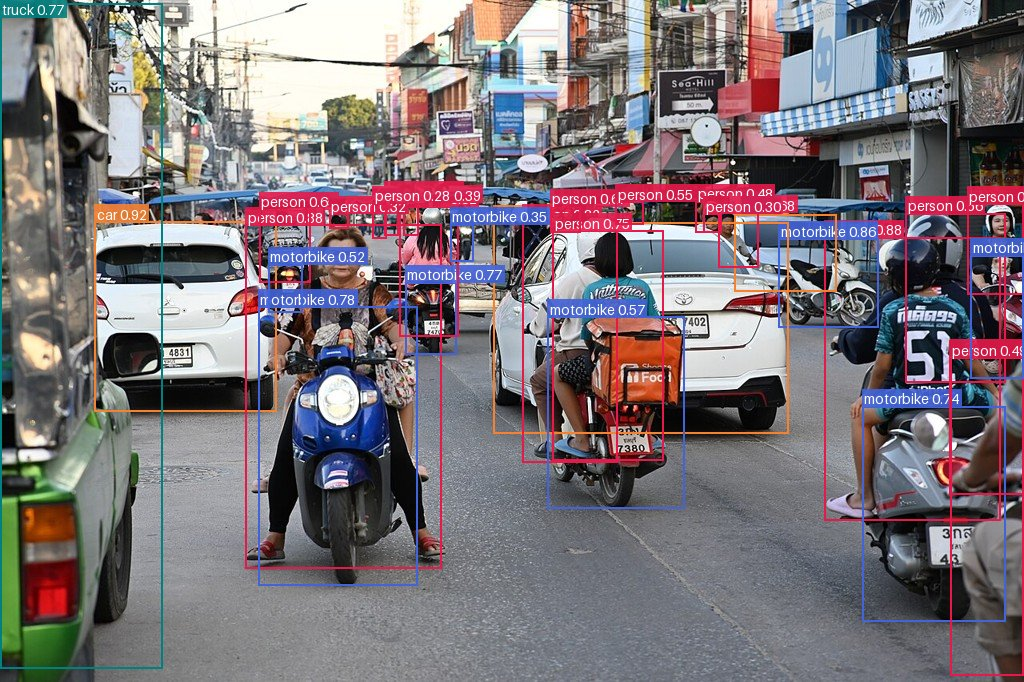

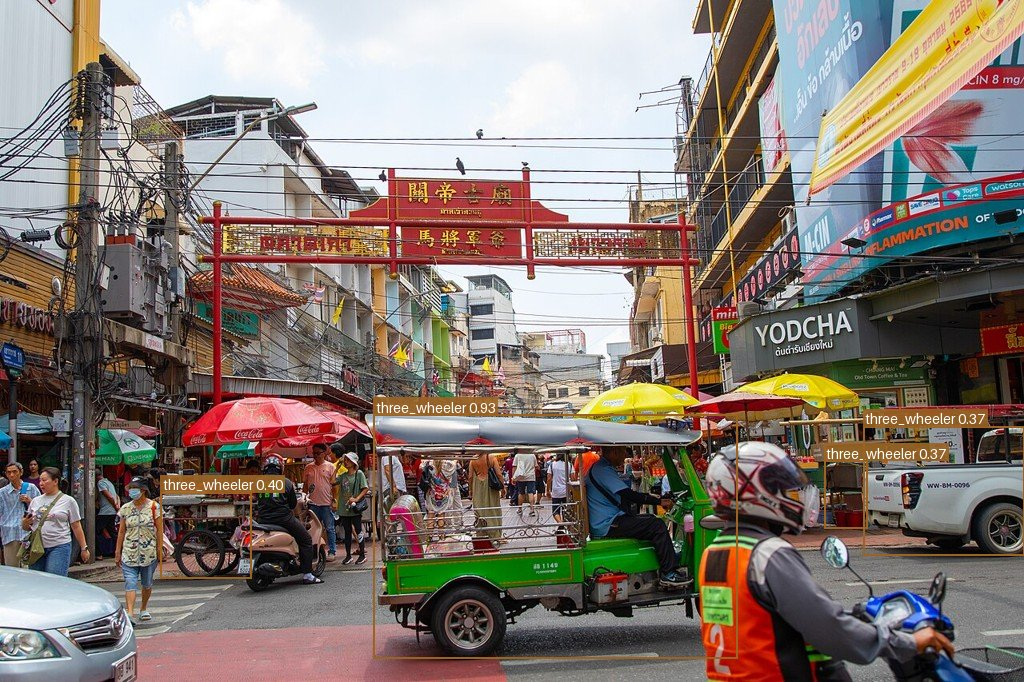

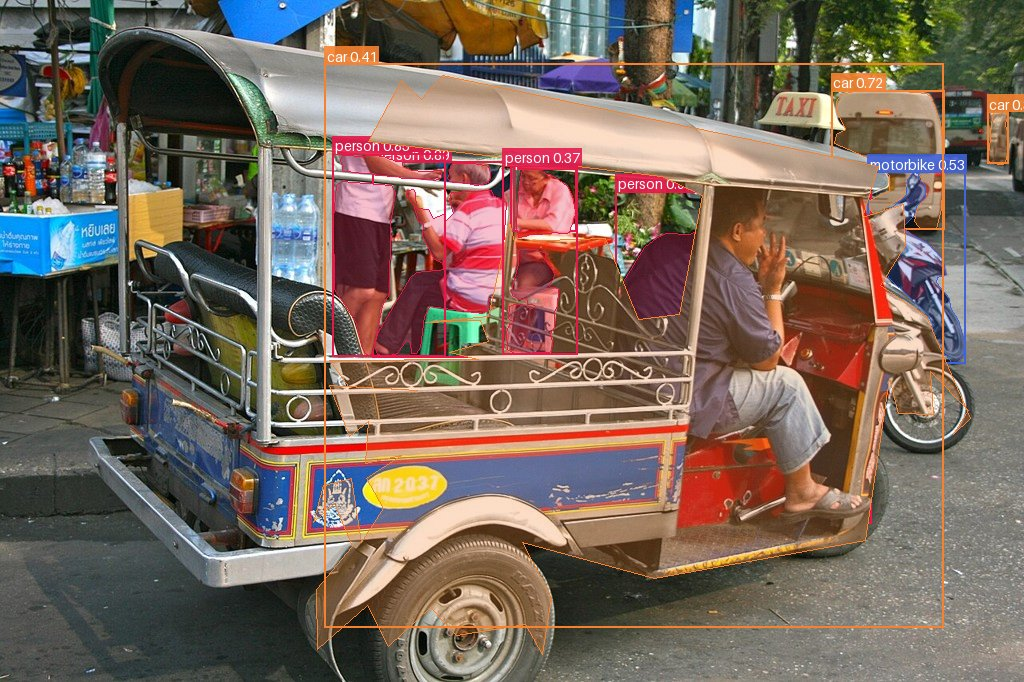

In [8]:
from IPython.display import Image, display
display(Image("work/prelabel/t_y26/viz/img_011.jpg"))
display(Image("work/prelabel/t_yoloe/viz/img_002.jpg"))
display(Image("work/prelabel/t_sam/viz/img_013.jpg"))

## 4. Chạy mọi ảnh ở ngưỡng thấp (nguồn cho Part 3, 4)
Chạy **sau khi** bạn đã gán xong 4 ảnh gold bằng tay (Part 1). Ảnh gold không bao giờ được xem pre-label trước khi gán xong.

In [9]:
!python scripts/prelabel.py --model yolo26 --size m --split all --conf 0.05 --out work/prelabel/y26_all --no-viz
!python scripts/prelabel.py --model yoloe --classes three_wheeler --split all --conf 0.05 --out work/prelabel/yoloe_all --no-viz

Model: yolo26 | thiết bị: cuda | 36 ảnh | ngưỡng mặc định 0.05
  img_001.jpg: 58 box
  img_002.jpg: 35 box
  img_003.jpg: 40 box
  img_004.jpg: 14 box
  img_005.jpg: 83 box
  img_006.jpg: 51 box
  img_007.jpg: 59 box
  img_008.jpg: 19 box
  img_009.jpg: 11 box
  img_010.jpg: 14 box
  img_011.jpg: 58 box
  img_012.jpg: 13 box
  img_013.jpg: 20 box
  img_014.jpg: 35 box
  img_015.jpg: 42 box
  img_016.jpg: 52 box
  img_017.jpg: 10 box
  img_018.jpg: 82 box
  img_019.jpg: 54 box
  img_020.jpg: 24 box
  img_021.jpg: 83 box
  img_022.jpg: 42 box
  img_023.jpg: 14 box
  img_024.jpg: 170 box
  img_025.jpg: 36 box
  img_026.jpg: 52 box
  img_027.jpg: 42 box
  img_028.jpg: 66 box
  img_029.jpg: 64 box
  img_030.jpg: 54 box
  img_031.jpg: 12 box
  img_032.jpg: 45 box
  img_033.jpg: 35 box
  img_034.jpg: 69 box
  img_035.jpg: 52 box
  img_036.jpg: 62 box

Đã ghi 1672 box (0 có mask) cho 36 ảnh -> work\prelabel\y26_all\pre.coco.json
Tên thô KHÔNG có trong ánh xạ (bị bỏ im lặng nếu bạn không đọc dò

d:\Vin\Day08\K5-L23-Day08-HoXuanHung-2A202603062-AI-Assisted-Labeling\.venv\Lib\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


## 5. Part 3 — tải kết quả thô về máy, quét ngưỡng ở máy bạn
Chạy ô dưới, tải `colab_stage1.zip`, giải nén vào repo trên máy, rồi chạy `threshold_sweep.py` (xem `docs/THRESHOLD.md`).

In [ ]:
!zip -rq colab_stage1.zip work/prelabel/y26_all work/prelabel/yoloe_all work/runs.csv
from google.colab import files
files.download("colab_stage1.zip")

ModuleNotFoundError: No module named 'google'

## 6. Part 4 — gộp batch với ngưỡng của bạn
Sau Part 3 (`threshold_sweep.py` chạy **trên máy bạn**), dán chuỗi ngưỡng vào `THR`. Cài **ảnh bẫy** (`inject_traps.py`) nên làm trên máy bạn để hạt giống và đáp án nằm trong repo của bạn.

In [ ]:
THR = "person=0.35,bicycle=0.3,motorbike=0.35,car=0.3,bus=0.3,truck=0.4,three_wheeler=0.35"   # <-- thay bằng ngưỡng của BẠN
!python scripts/merge_prelabels.py work/prelabel/yoloe_all/pre.coco.json work/prelabel/y26_all/pre.coco.json --thr "$THR" --conf 0.3 --iou 0.6 --split batch,gold --out work/prelabel/merged_review/pre.coco.json
# MSSV = "22001234"   # thay bằng MSHV của bạn rồi bỏ comment dòng dưới nếu muốn cài bẫy ở Colab
# !python scripts/inject_traps.py --pre work/prelabel/merged_review/pre.coco.json --student $MSSV

## 7. Part 5 — mask SAM cho 3 vật (bằng click)
Sửa toạ độ click theo vật bạn chọn; xem `docs/MODELS.md` mục B1.

In [ ]:
SAM = "sam2.1_b.pt"     # SAM 1: mobile_sam.pt | sam_b.pt ; SAM 2.1: sam2.1_t/s/b/l.pt
!python scripts/sam2_points.py --image img_013.jpg --pos "400,480" --pos "600,110" --neg "720,300" --sam $SAM --out submission/masks --name tuktuk_img013
from IPython.display import Image, display
display(Image("submission/masks/tuktuk_img013.jpg"))

## 8. Tải kết quả về máy
Gói `work/prelabel` (file nhãn), `work/runs.csv` (nhật ký lần chạy, để copy sang `model_log.csv`) và `submission/masks`. Giải nén vào **repo trên máy bạn**, giữ nguyên đường dẫn.

In [ ]:
!zip -rq colab_outputs.zip work/prelabel work/runs.csv submission/masks 2>/dev/null || true
from google.colab import files
files.download("colab_outputs.zip")

**Tiếp theo (trên máy bạn):** giải nén `colab_outputs.zip` vào thư mục repo → làm theo `GUIDE.md` từ bước nạp vào CVAT. Nhớ: ghi `model_log.csv` bằng nhận xét **của bạn** khi nhìn ảnh `viz/`; số trong `runs.csv` do Colab chạy (ghi chú `device = cuda`, thời gian khác máy bạn).